## 1. Setup & load

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CSV = ROOT / "Output" / "sweep_ml.csv"

df = pd.read_csv(CSV)
print(f"Loaded {len(df):,} rows x {df.shape[1]} cols from {CSV.name}")
print(f"Profiles: {df['profile_id'].nunique()} | models: {df['xml_file'].nunique()} "
      f"| volumes: {df['data_volume'].nunique()} | servers: {df['servers'].nunique()}")

Loaded 567,000 rows x 111 cols from sweep_ml.csv
Profiles: 100 | models: 135 | volumes: 6 | servers: 7


## 2. The features and targets

- **Targets (3):** `total_time_cost`, `total_environmental_cost`, `total_financial_cost`
- **Profile features (18, constant within a profile):** 8 selectivities, 8 index flags, customer_count, order_count
- **Within-profile axes:** `data_volume`, `servers`, and the model structure (`xml_file`, 135 models)

We **exclude** the per-query cost columns (`q*_time_cost`, ...) — they aggregate into
the targets, so using them would be target leakage.

In [3]:
COLS8 = ['w_name','w_city','w_tax','c_last','balance','c_credit','o_carrier_id','o_ol_cnt']
TARGETS = ['total_time_cost','total_environmental_cost','total_financial_cost']

feat_num = ['customer_count','order_count','data_volume','servers']
feat_sel = [f'sel_{c}' for c in COLS8]
feat_idx = [f'idx_{c}' for c in COLS8]
FEATURES = feat_num + feat_sel + feat_idx + ['model_code']

# encode the 135 models as integer codes (structure matters a lot for cost)
df['model_code'] = df['xml_file'].astype('category').cat.codes
print('Feature count:', len(FEATURES))
print(FEATURES)

Feature count: 21
['customer_count', 'order_count', 'data_volume', 'servers', 'sel_w_name', 'sel_w_city', 'sel_w_tax', 'sel_c_last', 'sel_balance', 'sel_c_credit', 'sel_o_carrier_id', 'sel_o_ol_cnt', 'idx_w_name', 'idx_w_city', 'idx_w_tax', 'idx_c_last', 'idx_balance', 'idx_c_credit', 'idx_o_carrier_id', 'idx_o_ol_cnt', 'model_code']


## 3. Why we must log-transform the targets

The targets span ~15 orders of magnitude (driven by the 1K→100M volume sweep). On a
linear scale, MSE is dominated by the largest values and the model ignores everything
else. We train on `log1p(y)` and report metrics in log space.

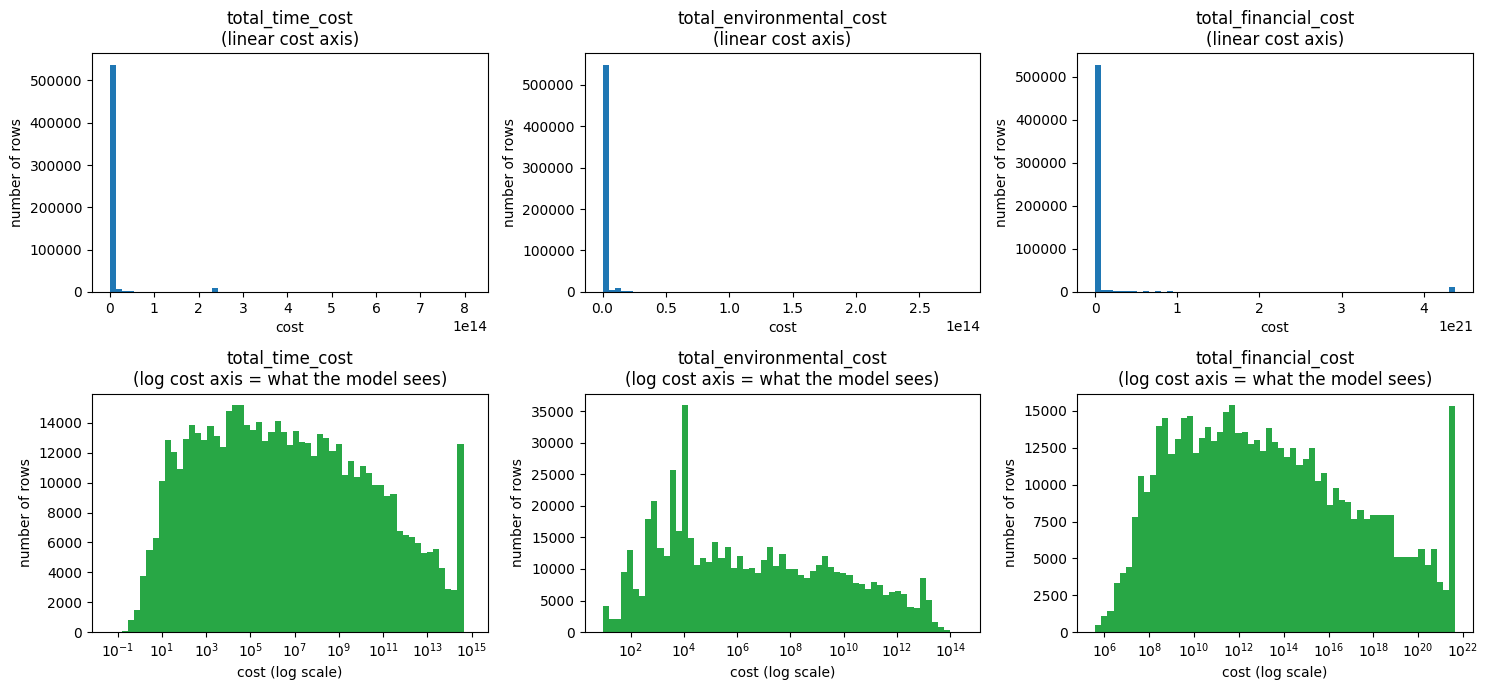

Both rows: identical data and identical y-axis (row count).
The ONLY difference is the x-axis scale: linear (top) vs log (bottom).
On the linear axis every row piles into one bar; the log axis spreads them out.

Target ranges (raw):
  total_time_cost              min=0.0444  max=8.11e+14
  total_environmental_cost     min=8.77  max=2.84e+14
  total_financial_cost         min=3.91e+05  max=4.38e+21


In [4]:
# Fair before/after: SAME data, SAME y-axis (row count), only the x-axis SCALE changes.
# Top    = linear cost axis  -> all 567k rows collapse into one bar (unusable for ML).
# Bottom = log cost axis     -> the same data spreads out (this is what log1p gives the model).
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, t in enumerate(TARGETS):
    data = df[t].values
    # TOP: linear x-axis
    axes[0, j].hist(data, bins=60, color='#1f77b4')
    axes[0, j].set_title(f'{t}\n(linear cost axis)')
    axes[0, j].set_xlabel('cost'); axes[0, j].set_ylabel('number of rows')
    # BOTTOM: same data, same y-axis, x-axis now LOG-scaled (log-spaced bins)
    bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 60)
    axes[1, j].hist(data, bins=bins, color='#28a745')
    axes[1, j].set_xscale('log')
    axes[1, j].set_title(f'{t}\n(log cost axis = what the model sees)')
    axes[1, j].set_xlabel('cost (log scale)'); axes[1, j].set_ylabel('number of rows')
plt.tight_layout(); plt.show()

print('Both rows: identical data and identical y-axis (row count).')
print('The ONLY difference is the x-axis scale: linear (top) vs log (bottom).')
print('On the linear axis every row piles into one bar; the log axis spreads them out.')
print()
print('Target ranges (raw):')
for t in TARGETS:
    print(f'  {t:28s} min={df[t].min():.3g}  max={df[t].max():.3g}')

## 4. Train/test split — by PROFILE, not by row

All 18 profile features are identical across a profile's 5,670 rows. A random row split
would leak profile identity into the test set and inflate scores. We hold out **whole
profiles** with `GroupShuffleSplit(groups=profile_id)` — this measures the real target:
*can the model predict cost for a profile it has never seen?*

In [5]:
X = df[FEATURES].copy()
for c in ['customer_count','order_count','data_volume']:
    X[c] = np.log1p(X[c])   # log-transform skewed numeric features

groups = df['profile_id'].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, np.zeros(len(X)), groups=groups))
print(f"Train rows: {len(train_idx):,} ({df.iloc[train_idx]['profile_id'].nunique()} profiles)")
print(f"Test  rows: {len(test_idx):,} ({df.iloc[test_idx]['profile_id'].nunique()} profiles held out)")
print("Held-out profiles:", sorted(df.iloc[test_idx]['profile_id'].unique()))

Train rows: 453,600 (80 profiles)
Test  rows: 113,400 (20 profiles held out)
Held-out profiles: ['S00', 'S04', 'S10', 'S12', 'S18', 'S22', 'S30', 'S31', 'S33', 'S39', 'S44', 'S45', 'S53', 'S70', 'S73', 'S76', 'S77', 'S80', 'S83', 'S90']


## 5. Baseline RandomForest — one model per target

In [6]:
models = {}
rows = []
for t in TARGETS:
    y = np.log1p(df[t].values)
    m = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)
    m.fit(X.iloc[train_idx], y[train_idx])
    pred = m.predict(X.iloc[test_idx])
    r2 = r2_score(y[test_idx], pred)
    mae = mean_absolute_error(y[test_idx], pred)
    models[t] = m
    rows.append({'target': t, 'R2_log': round(r2, 4), 'MAE_log': round(mae, 4)})
results = pd.DataFrame(rows)
results

MemoryError: could not allocate 67108864 bytes

**Reading the scores:** R² is in log space. >0.8 means the swept parameters are
strongly predictive of cost (Verification V6). MAE in log space ≈ typical multiplicative
error: MAE=0.1 ≈ ~10% off, MAE=0.7 ≈ ~2× off.

## 6. Feature importance — what drives cost?

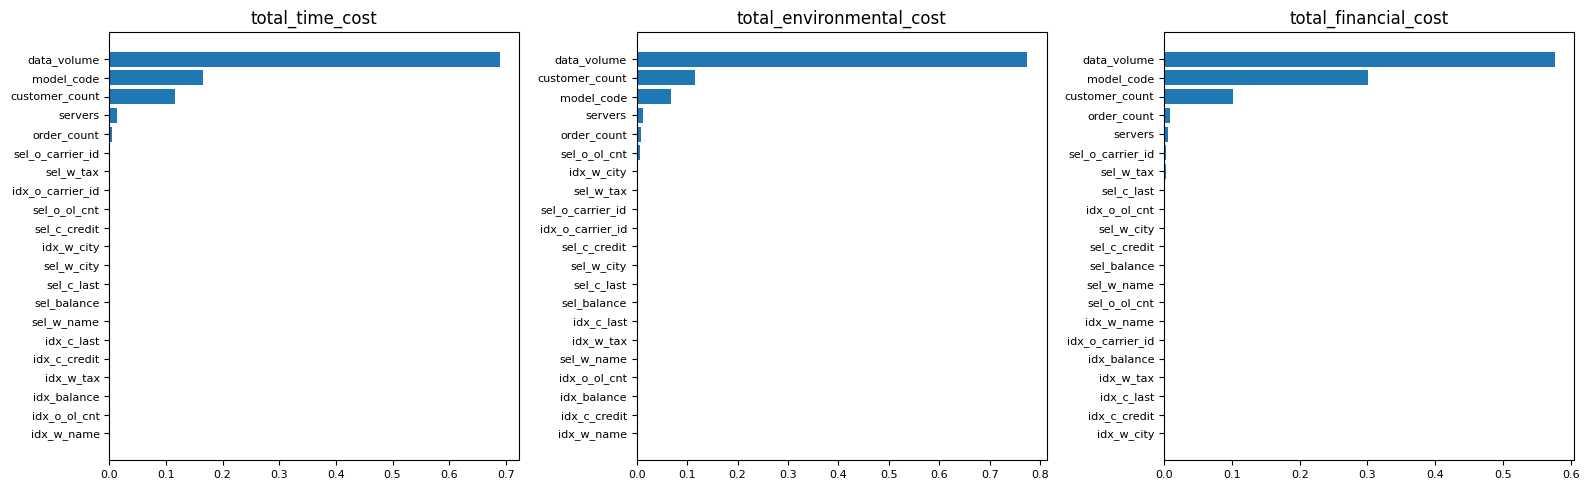

Top 8 features for total_time_cost:


data_volume         0.689552
model_code          0.165638
customer_count      0.115067
servers             0.014009
order_count         0.005565
sel_o_carrier_id    0.001972
sel_w_tax           0.001397
idx_o_carrier_id    0.001058


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(axes, TARGETS):
    imp = pd.Series(models[t].feature_importances_, index=FEATURES).sort_values()
    ax.barh(imp.index, imp.values, color='#1f77b4')
    ax.set_title(t); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

print('Top 8 features for total_time_cost:')
print(pd.Series(models['total_time_cost'].feature_importances_, index=FEATURES)
      .sort_values(ascending=False).head(8).to_string())

## 7. Predicted vs. actual (held-out profiles)

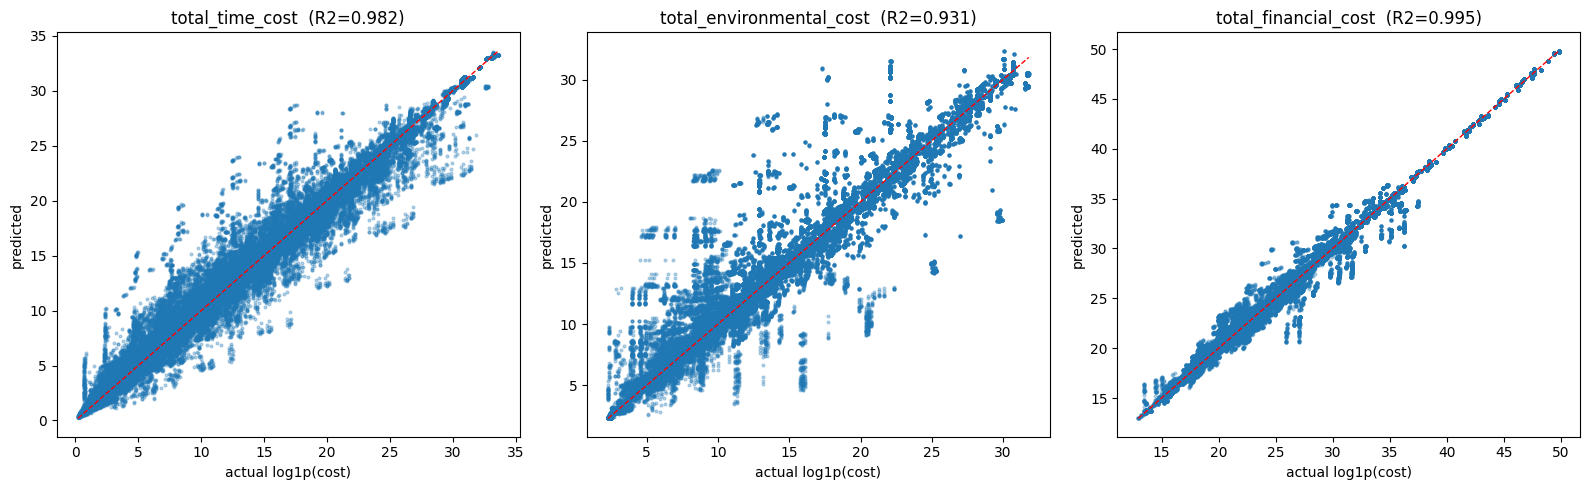

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(axes, TARGETS):
    y = np.log1p(df[t].values)
    pred = models[t].predict(X.iloc[test_idx])
    ax.scatter(y[test_idx], pred, s=4, alpha=0.3, color='#1f77b4')
    lo, hi = y[test_idx].min(), y[test_idx].max()
    ax.plot([lo, hi], [lo, hi], 'r--', lw=1)
    ax.set_xlabel('actual log1p(cost)'); ax.set_ylabel('predicted')
    ax.set_title(f'{t}  (R2={r2_score(y[test_idx], pred):.3f})')
plt.tight_layout(); plt.show()

## 8. Error analysis — which held-out profiles predict worst?

In [ ]:
t = 'total_time_cost'
y = np.log1p(df[t].values)
pred_all = np.full(len(df), np.nan)
pred_all[test_idx] = models[t].predict(X.iloc[test_idx])
err = pd.DataFrame({
    'profile_id': df.iloc[test_idx]['profile_id'].values,
    'abs_err': np.abs(y[test_idx] - pred_all[test_idx]),
})
print('Mean abs error (log) per held-out profile:')
print(err.groupby('profile_id')['abs_err'].mean().sort_values(ascending=False).to_string())

Mean abs error (log) per held-out profile:
profile_id
S90    1.247778
S33    1.240221
S22    1.102268
S76    0.985778
S12    0.950019
S00    0.753322
S77    0.634651
S10    0.587929
S30    0.547029
S83    0.543054
S04    0.449261
S80    0.448877
S73    0.437274
S18    0.402873
S70    0.394186
S53    0.370257
S44    0.341933
S31    0.321576
S39    0.306879
S45    0.266993


## 9. Conclusions & next steps

**Findings (N=100 profiles, 20 held-out, metrics in log space):**

- **Baseline R² / MAE per target** (from §5):

  | Target | R² (log) | MAE (log) | ≈ typical error |
  |---|---|---|---|
  | total_time_cost | 0.982 | 0.62 | ~1.85× |
  | total_environmental_cost | 0.931 | 0.97 | ~2.6× |
  | total_financial_cost | 0.995 | 0.35 | ~1.4× |


- **Dominant cost drivers** (feature importance, `total_time_cost`, from §6):
  `data_volume` (0.69) ≫ `model_code`/structure (0.17) > `customer_count` (0.115) >
  `servers` (0.014) > `order_count` (0.006) > selectivities (<0.002 each).
  These are exactly the physical cost drivers → strong semantic validation. Note
  `customer_count` is a genuine #3 driver (not a dead feature); selectivities are
  secondary within their realistic per-column ranges.

- **Where it struggles** (from §8): error concentrates on **structural-outlier
  profiles** (worst: S90 1.25, S33 1.24) — extreme count-ratio corners that are
  thinly sampled. Best profiles (S45 0.27) sit in the dense middle. The model has a
  *coverage gap at the extremes*, not a structural flaw.

- **Scaling effect (N=25 → N=100):** MAE roughly halved (time 1.04→0.62; financial
  0.73→0.35), confirming more profiles tighten predictions — the data-backed argument
  for a larger sweep.

**Next steps**
1. **Scale the sweep further** — 100 → 500+ profiles to shrink the remaining error on
   outlier corners 
2. **Tune & compare** — XGBoost / gradient boosting vs. RandomForest; 
3. **Multi-output** — predict all 3 targets jointly (they're correlated).
4. **Scenario layer** — add query-frequency variation (`lib/scenarios.py`) for temporal
   generalisation, and a per-query cost model to handle *new* queries (per-query cost
   columns in the CSV are its targets).
